# Portfolio 3: Load-Class Forecasting with Traditional ML and LSTM (Zone 1, Tetouan City)

This notebook continues Portfolio 1 (EDA) and Portfolio 2 (K-means load classes, feature engineering, DT/SVM).
The task here is **classification**: predict the Zone 1 load class (`Base Load`, `Normal Load`, `Peak Load`) **1 hour ahead**.

- **Part A** – Random Forest and MLP classifiers on tabular features.
- **Part B** – LSTM classifier on sequences of past observations.
- **Part C** – Master results table and reflection.

Kernel: conda env `aistuff` (Python 3.11, scikit-learn, TensorFlow/Keras).

In [1]:
import os, time, pickle, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, log_loss,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
for d in ['figures', 'models', 'results']:
    os.makedirs(d, exist_ok=True)

CLASS_NAMES = ['Base Load', 'Normal Load', 'Peak Load']
H = 6  # forecast horizon: 6 steps x 10 min = 1 hour ahead

## 1. Load and Analyse the Dataset (Step A.1)

The raw file gives the timestamp and the continuous Zone 1 load (kW). The class labels are the 3 K-means classes created in Portfolio 2
(`converted_power_consumption.csv`, same row order as the raw file). The target `zone_1_load_class` is categorical, so this is a
**classification problem**. Column cleaning and the `hour`/`month` extraction follow Portfolio 1/2.

In [2]:
raw = pd.read_csv('../data/Tetuan City power consumption.csv')
labels = pd.read_csv('../data/converted_power_consumption.csv')

# Same snake_case cleaning as Portfolio 1/2
raw.columns = (raw.columns.str.strip().str.replace(r'\s+', ' ', regex=True)
               .str.lower().str.replace(' ', '_'))
raw['datetime'] = pd.to_datetime(raw['datetime'])
raw['hour'] = raw['datetime'].dt.hour
raw['month'] = raw['datetime'].dt.month

df = raw.drop(columns=['zone_2_power_consumption', 'zone_3_power_consumption'])
df['zone_1_load_class'] = labels['zone_1_load_class'].values  # Portfolio 2 K-means labels

print('Shape:', df.shape)
print('Rows in chronological order:', df['datetime'].is_monotonic_increasing)
display(df.head())
display(df['zone_1_load_class'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))))

Shape: (52416, 10)
Rows in chronological order: True


,datetime,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,zone_1_power_consumption,hour,month,zone_1_load_class
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,0,1,1
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,0,1,1
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,0,1,1
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,0,1,0
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,0,1,0


zone_1_load_class
Base Load      18099
Normal Load    21888
Peak Load      12429
Name: count, dtype: int64

## 2. Problem Framing: Chronological Split and 1-Hour Horizon

Readings 10 minutes apart are almost identical, so a shuffled split (used in Portfolio 2) lets the model see near-copies of test rows during
training. Because an LSTM needs ordered sequences, **all models in this notebook use the same chronological 80/20 split**: the first 80% of
the year is used for training and the last 20% (mid-October to December) for testing.

The task is to predict the class **1 hour ahead** (`class[t+6]`) using information available up to time `t`. Predicting the very next
10-minute step is trivial because the class changes on only ~3.5% of steps. The naive baselines below set the bar any model has to beat.

Train period: 2017-01-01 00:00:00 -> 2017-10-19 04:30:00
Test period : 2017-10-19 04:40:00 -> 2017-12-30 23:50:00


,Overall,Train (first 80%),Test (last 20%)
Base Load,34.5,31.7,45.7
Normal Load,41.8,41.9,41.0
Peak Load,23.7,26.3,13.3


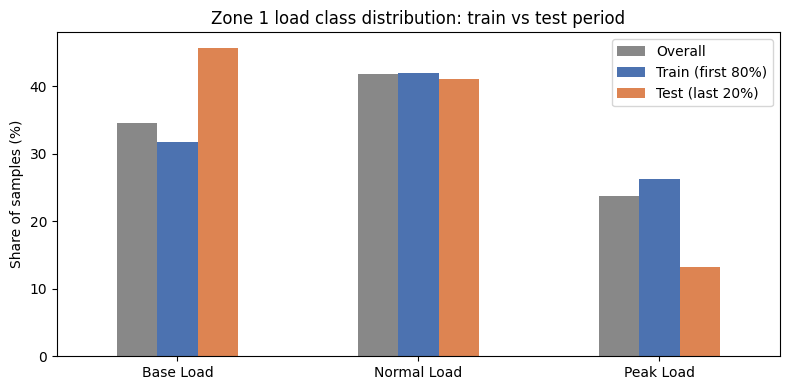

,Test accuracy
Persistence (10 min ago),0.9693
Persistence-1h (class at t),0.8283
Seasonal-24h (same time yesterday),0.8946


Share of 10-min steps where the class changes: 0.0346


In [3]:
N = len(df)
SPLIT = int(N * 0.8)  # first time index whose class belongs to the test period
y_all = df['zone_1_load_class'].values
print(f'Train period: {df.datetime[0]} -> {df.datetime[SPLIT - 1]}')
print(f'Test period : {df.datetime[SPLIT]} -> {df.datetime[N - 1]}')

dist = pd.DataFrame({
    'Overall': np.bincount(y_all) / N * 100,
    'Train (first 80%)': np.bincount(y_all[:SPLIT]) / SPLIT * 100,
    'Test (last 20%)': np.bincount(y_all[SPLIT:]) / (N - SPLIT) * 100,
}, index=CLASS_NAMES)
display(dist.round(1))

ax = dist.plot(kind='bar', figsize=(8, 4), rot=0, color=['#888888', '#4C72B0', '#DD8452'])
ax.set_ylabel('Share of samples (%)')
ax.set_title('Zone 1 load class distribution: train vs test period')
plt.tight_layout()
plt.savefig('figures/p3_class_shift.png', dpi=150)
plt.show()

# Naive baselines on the test targets class[t+H]
test_t = np.arange(SPLIT - H, N - H)  # anchor times whose target falls in the test period
y_test_ref = y_all[test_t + H]
baselines = {
    'Persistence (10 min ago)': y_all[test_t + H - 1],
    'Persistence-1h (class at t)': y_all[test_t],
    'Seasonal-24h (same time yesterday)': y_all[test_t + H - 144],
}
display(pd.DataFrame({'Test accuracy': {k: accuracy_score(y_test_ref, v) for k, v in baselines.items()}}).round(4))
print('Share of 10-min steps where the class changes:', round((y_all[1:] != y_all[:-1]).mean(), 4))

## 3. Part A: Traditional ML Models

### 3.1 Feature sets (Step A.2)
Two feature sets are compared so that we can separate the effect of *load history* from the effect of the *model*:

- **Set A – weather + time (16 features)**: the 7 original predictors plus the 9 engineered features from Portfolio 2 Task 3
  (recomputed here in raw units, because P3 requires scalers fitted on the training period only).
- **Set B – Set A + load history (22 features)**: adds the Zone 1 load at `t`, `t-10 min`, `t-1 h`, `t-24 h`, the 1-hour rolling mean and the
  1-hour change. These are all known at time `t`, so there is no leakage. The LSTM in Part B sees the same kind of history.

The first 144 rows (24 h) are dropped because `load_t-144` needs one day of history, and the last 6 rows have no target 1 h ahead.

In [4]:
feat = df.copy()

# Engineered features from Portfolio 2 (Task 3)
feat['diffuse_fraction'] = feat['diffuse_flows'] / (feat['general_diffuse_flows'] + 1e-5)
feat['temp_humidity_index'] = feat['temperature'] * feat['humidity']
feat['solar_thermal_load'] = feat['general_diffuse_flows'] * feat['temperature']
feat['convective_cooling_ratio'] = feat['temperature'] / (feat['wind_speed'] + 1.0)
feat['hour_sin'] = np.sin(2 * np.pi * feat['hour'] / 24)
feat['hour_cos'] = np.cos(2 * np.pi * feat['hour'] / 24)
feat['month_sin'] = np.sin(2 * np.pi * (feat['month'] - 1) / 12)
feat['month_cos'] = np.cos(2 * np.pi * (feat['month'] - 1) / 12)
feat['is_evening_peak'] = feat['hour'].between(17, 22).astype(int)

# Load history known at time t
load = feat['zone_1_power_consumption']
feat['load_t'] = load
feat['load_t-1'] = load.shift(1)
feat['load_t-6'] = load.shift(6)
feat['load_t-144'] = load.shift(144)
feat['load_roll_mean_6'] = load.rolling(6).mean()
feat['load_diff_6'] = load - load.shift(6)

feat['target'] = feat['zone_1_load_class'].shift(-H)  # class 1 hour ahead

SET_A = ['temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'hour', 'month',
         'diffuse_fraction', 'temp_humidity_index', 'solar_thermal_load', 'convective_cooling_ratio',
         'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_evening_peak']
SET_B = SET_A + ['load_t', 'load_t-1', 'load_t-6', 'load_t-144', 'load_roll_mean_6', 'load_diff_6']
FEATURE_SETS = {'Set A (weather+time)': SET_A, 'Set B (+load history)': SET_B}

data = feat.iloc[144:N - H]
print('Modelling rows:', data.shape[0], '| Missing values:', data[SET_B + ['target']].isna().sum().sum())

Modelling rows: 52266 | Missing values: 0


### 3.2 Scaling and chronological 80/20 split (Step A.2)
A sample anchored at `t` goes to the test set when its target time `t+6` is in the last 20% of the year. `StandardScaler` is fitted on the
training rows only and then applied to the test rows.

In [5]:
train = data[data.index + H < SPLIT]
test = data[data.index + H >= SPLIT]
y_train = train['target'].astype(int).values
y_test = test['target'].astype(int).values

X = {}
for name, cols in FEATURE_SETS.items():
    scaler = StandardScaler().fit(train[cols])
    X[name] = (scaler.transform(train[cols]), scaler.transform(test[cols]))
    print(f'{name}: X_train {X[name][0].shape}, X_test {X[name][1].shape}')
print('y_train', y_train.shape, '| y_test', y_test.shape)
print('Test targets identical to baseline targets:', np.array_equal(y_test, y_test_ref))

Set A (weather+time): X_train (41782, 16), X_test (10484, 16)


Set B (+load history): X_train (41782, 22), X_test (10484, 22)
y_train (41782,) | y_test (10484,)
Test targets identical to baseline targets: True


### 3.3 Train the two models (Step A.3)
- **Random Forest**: 300 trees, `min_samples_leaf=5` to stop the trees memorising single noisy readings (the DT overfitting issue in Portfolio 2).
- **MLP Classifier**: two hidden layers (64, 32), ReLU, Adam, L2 `alpha=1e-4`, early stopping on a 10% validation split.

Each model is trained on both feature sets (4 fits).

In [6]:
def make_models():
    return {
        'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
        'MLP': MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', alpha=1e-4,
                             early_stopping=True, validation_fraction=0.1, max_iter=300, random_state=SEED),
    }

def evaluate(name, model_type, y_true, y_pred, proba=None):
    return {'Model type': model_type, 'Model': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Weighted F1': f1_score(y_true, y_pred, average='weighted'),
            'Macro F1': f1_score(y_true, y_pred, average='macro'),
            'Peak recall': recall_score(y_true, y_pred, labels=[2], average=None)[0],
            'Test log loss': log_loss(y_true, proba, labels=[0, 1, 2]) if proba is not None else np.nan}

results = [evaluate(k, 'Naive baseline', y_test_ref, v)
           for k, v in baselines.items() if k != 'Persistence (10 min ago)']
partA_preds = {}
for set_name, (Xtr, Xte) in X.items():
    for model_name, model in make_models().items():
        t0 = time.time()
        model.fit(Xtr, y_train)
        name = f'{model_name} - {set_name}'
        partA_preds[name] = model.predict(Xte)
        results.append(evaluate(name, 'Traditional ML', y_test, partA_preds[name], model.predict_proba(Xte)))
        print(f'{name}: fitted in {time.time() - t0:.1f}s, test accuracy {results[-1]["Accuracy"]:.4f}')

Random Forest - Set A (weather+time): fitted in 1.3s, test accuracy 0.7930


MLP - Set A (weather+time): fitted in 3.2s, test accuracy 0.7912


Random Forest - Set B (+load history): fitted in 1.5s, test accuracy 0.9040


MLP - Set B (+load history): fitted in 6.5s, test accuracy 0.8899


### 3.4 Evaluation and 5-fold cross-validation (Step A.4)
Cross-validation uses `TimeSeriesSplit(n_splits=5)` on the training period: each fold trains on the past and validates on the following
block, which respects time order. The scaler is inside a pipeline, so it is refitted on each training fold.

In [7]:
tscv = TimeSeriesSplit(n_splits=5)
cv_scores = {}
for set_name, cols in FEATURE_SETS.items():
    for model_name, model in make_models().items():
        scores = cross_val_score(make_pipeline(StandardScaler(), model), train[cols], y_train,
                                 cv=tscv, scoring='accuracy', n_jobs=-1 if model_name == 'MLP' else None)
        cv_scores[f'{model_name} - {set_name}'] = scores

for r in results:
    s = cv_scores.get(r['Model'])
    r['CV accuracy (mean)'] = s.mean() if s is not None else np.nan
    r['CV accuracy (std)'] = s.std() if s is not None else np.nan

partA_table = pd.DataFrame(results).set_index('Model')
display(partA_table.drop(columns='Model type').round(4))
display(pd.DataFrame(cv_scores, index=[f'Fold {i + 1}' for i in range(5)]).T.round(4))

,Accuracy,Weighted F1,Macro F1,Peak recall,Test log loss,CV accuracy (mean),CV accuracy (std)
Model,,,,,,,
Persistence-1h (class at t),0.8283,0.8283,0.7994,0.7115,NaN,NaN,NaN
Seasonal-24h (same time yesterday),0.8946,0.8947,0.8879,0.8777,NaN,NaN,NaN
Random Forest - Set A (weather+time),0.7930,0.7999,0.7780,0.8835,0.6424,0.7581,0.1198
MLP - Set A (weather+time),0.7912,0.7942,0.7908,0.9374,0.8167,0.6920,0.0941
Random Forest - Set B (+load history),0.9040,0.9062,0.8837,0.8899,0.2253,0.9029,0.0483
MLP - Set B (+load history),0.8899,0.8930,0.8637,0.9719,0.3799,0.8621,0.0466


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Random Forest - Set A (weather+time),0.9108,0.8967,0.6618,0.6829,0.6384
MLP - Set A (weather+time),0.7175,0.8528,0.6898,0.6200,0.5799
Random Forest - Set B (+load history),0.9463,0.9499,0.8180,0.8865,0.9135
MLP - Set B (+load history),0.8570,0.9453,0.8439,0.8024,0.8618


In [8]:
best_A = partA_table[partA_table['Model type'] == 'Traditional ML']['Accuracy'].idxmax()
print('Best traditional model:', best_A)
print(classification_report(y_test, partA_preds[best_A], target_names=CLASS_NAMES, digits=4))

Best traditional model: Random Forest - Set B (+load history)
              precision    recall  f1-score   support

   Base Load     0.9954    0.9121    0.9520      4791
 Normal Load     0.8709    0.8996    0.8850      4303
   Peak Load     0.7502    0.8899    0.8141      1390

    accuracy                         0.9040     10484
   macro avg     0.8722    0.9006    0.8837     10484
weighted avg     0.9118    0.9040    0.9062     10484



### 3.5 Visualise results (Step A.5)

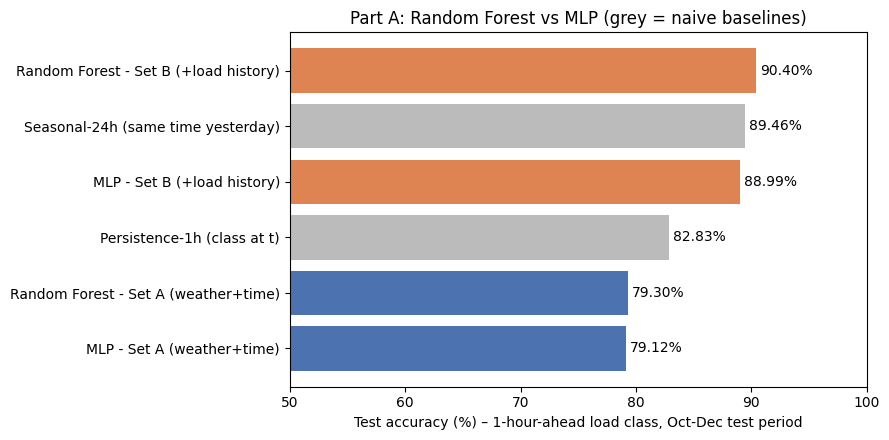

In [9]:
plot_df = partA_table[['Accuracy', 'Weighted F1']].sort_values('Accuracy')
colors = ['#BBBBBB' if 'Persistence' in i or 'Seasonal' in i else ('#4C72B0' if 'Set A' in i else '#DD8452')
          for i in plot_df.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(plot_df.index, plot_df['Accuracy'] * 100, color=colors)
ax.bar_label(bars, fmt='%.2f%%', padding=3)
ax.set_xlim(50, 100)
ax.set_xlabel('Test accuracy (%) – 1-hour-ahead load class, Oct-Dec test period')
ax.set_title('Part A: Random Forest vs MLP (grey = naive baselines)')
plt.tight_layout()
plt.savefig('figures/p3_partA_bar.png', dpi=150)
plt.show()

### 3.6 Part A observations
- **Best traditional model: Random Forest on Set B** (90.40% accuracy, 0.906 weighted F1, TimeSeriesSplit CV 90.29% ± 4.83%).
- **Load history matters most.** Adding past load lifts both models by ~10-11 points (RF 79.30% -> 90.40%, MLP 79.12% -> 88.99%).
  Weather and time alone cannot beat even the 1-hour persistence baseline (82.83%).
- **Only a small margin over the naive seasonal baseline.** "Same class as 24 h ago" already scores 89.46%, so the RF adds ~1 point. Most
  of the predictability comes from the daily cycle.
- **Why RF beats MLP:** the class boundaries are thresholds on load and hour, which trees model directly with axis-aligned splits. Bagging
  300 trees with `min_samples_leaf=5` reduces the variance that hurt the single Decision Tree in Portfolio 2. The MLP needs more tuning and
  ends with a higher test log loss (0.38 vs 0.23).
- **Time-based CV is less stable than P2's shuffled CV.** Set A folds range from 64% to 91%, because later folds (autumn) differ from the
  winter/spring folds the model was trained on. This is the seasonal drift a random split would hide.